<a href="https://colab.research.google.com/github/agmbabazi/summative_intro_to_ml/blob/main/Summative_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Introduction**

## Evaluating Traditional Machine Learning and Deep Learning for Classifying Elevated Depressive Symptoms

This project compares traditional machine learning and deep learning models
for classifying elevated depressive symptoms.

The dataset comes from NHANES and contains demographic information,
socioeconomic information, body measurements, and responses to a depression
screening questionnaire.

The goal is to investigate whether the selected features can help distinguish
participants whose PHQ-9 score is below 10 from those whose score is 10 or
higher.

I will compare Logistic Regression, Random Forest, and a neural network.
I will also investigate whether grouping age, changing Random Forest
parameters, and using class weights improve the results.

Because the positive class is much smaller than the negative class, I will
evaluate more than accuracy. Precision, recall, F1-score, ROC-AUC, and PR-AUC
will help me understand how well each model identifies the positive class.

The target represents elevated depressive symptoms based on questionnaire
responses. It is not a clinical diagnosis.

# **2. Import and configurations**

This section imports the libraries needed for data handling, visualization,
preprocessing, model training, and evaluation.

Pandas and NumPy help me work with the data. Matplotlib and Seaborn are used
to visualize patterns. Scikit-learn provides preprocessing tools, traditional
machine learning models, and evaluation metrics. TensorFlow and Keras are
used to build the neural network.

I set a random seed so that random operations, such as splitting the data and
initializing the neural network, are more reproducible. A fixed seed does not
guarantee identical results in every computing environment, but it helps
make comparisons fairer.

## Import libraries

In [90]:
import os
import time
import random
import zipfile
import warnings
from io import BytesIO

import numpy as np
import pandas as pd
import requests
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## configuration and random seeds

In [91]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

### Output folders

I create separate folders for the data, saved models, figures, tables, and
training logs.

Keeping these outputs organized makes it easier to find the results,
include figures in the report, and reproduce the experiment without mixing
generated files with the notebook code.

In [92]:
OUTPUT_DIR = "outputs"
DATA_DIR = os.path.join(OUTPUT_DIR, "data")
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")
LOG_DIR = os.path.join(OUTPUT_DIR, "logs")          # TensorBoard logs
for folder in [DATA_DIR, MODEL_DIR, FIG_DIR, TABLE_DIR, LOG_DIR]:
    os.makedirs(folder, exist_ok=True)

### Data configuration

These variables define the survey cycles, questionnaire columns, target
threshold, minimum age, feature columns, and data split proportions.

Defining them in one place reduces repeated values throughout the notebook.
For example, if I need to change the target threshold, I can do so in the
configuration instead of searching through several cells.

In [93]:
CYCLES = [(2005, "D"), (2007, "E"), (2009, "F"), (2011, "G"),
          (2013, "H"), (2015, "I"), (2017, "J")]        # ordered list, NOT a set

PHQ9_COLS = [f"DPQ{n:03d}" for n in range(10, 100, 10)]  # DPQ010 ... DPQ090
PHQ9_THRESHOLD = 10
MIN_AGE = 20

NUMERIC_FEATURES = ["RIDAGEYR", "INDFMPIR", "BMXBMI"]
CATEGORICAL_FEATURES = ["RIAGENDR", "RIDRETH1", "DMDEDUC2", "DMDMARTL"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET_NAMES = ["No elevated symptoms", "Elevated symptoms"]

### Split configuration

In [94]:
TEST_SIZE = 0.15
VAL_SIZE = 0.15

### Small helper used by every plotting cell

In [106]:
def save_fig(filename):
    # Tidy the layout, save the figure into outputs/figures, then show it.
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()

# **3. Dataset**

## Download datset

I use the public NHANES data files rather than relying on a manually edited
dataset. The data are downloaded from the official source so the collection
process can be repeated.

The download function reads each SAS transport file into a DataFrame.
The retry mechanism allows another attempt if a request fails because of a
temporary connection problem.

In [95]:
def download_xpt(year, filename, retries=3):
    # Download one NHANES .xpt file and return it as a DataFrame.
    # Retries a few times because public servers occasionally time out.
    url = f"https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{filename}.xpt"
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()
            return pd.read_sas(BytesIO(response.content), format="xport")
        except Exception as error:
            print(f"  attempt {attempt} failed for {filename}: {error}")
            if attempt == retries:
                raise
            time.sleep(3)

In [96]:
def download_cycle(year, suffix):
    # Download DEMO, DPQ and BMX for one cycle, keep the needed columns, and merge them.
    demo = download_xpt(year, f"DEMO_{suffix}")[
        ["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH1", "DMDEDUC2", "DMDMARTL", "INDFMPIR"]]
    dpq = download_xpt(year, f"DPQ_{suffix}")[["SEQN"] + PHQ9_COLS]
    bmx = download_xpt(year, f"BMX_{suffix}")[["SEQN", "BMXBMI"]]

    # Inner join with the questionnaire: we only want people who were asked the PHQ-9.
    # Left join with body measures: keep the person even if BMI was not measured.
    merged = demo.merge(dpq, on="SEQN", how="inner").merge(bmx, on="SEQN", how="left")
    merged["survey_cycle"] = f"{year}-{year + 1}"
    return merged

## Download every cycle and stack them

The demographic, depression questionnaire, and body measurement information
are stored in separate files.

I merge them using SEQN, which identifies a participant within the survey
data. The depression questionnaire is joined using an inner join so that
participants without a corresponding questionnaire record are not included
in the merged dataset. Body measurements are joined using a left join so
that participants are retained even if BMI is missing.

I repeat this process for each selected survey cycle and then combine the
cycles into one dataset.

In [97]:
cycle_frames = []
for year, suffix in CYCLES:
    print(f"Downloading cycle {year}-{year + 1} ...")
    cycle_frames.append(download_cycle(year, suffix))

raw_df = (pd.concat(cycle_frames, ignore_index=True)
            .sort_values("SEQN")
            .reset_index(drop=True))
print("\nDownload and merge complete.")
display(raw_df.head())


Download and merge complete.


,SEQN,RIDAGEYR,RIAGENDR,RIDRETH1,DMDEDUC2,DMDMARTL,INDFMPIR,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,BMXBMI,survey_cycle
0,31130.0,85.0,2.0,3.0,4.0,2.0,1.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2005-2006
1,31131.0,44.0,2.0,4.0,4.0,1.0,4.65,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,30.90,2005-2006
2,31132.0,70.0,1.0,3.0,5.0,1.0,5.00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,24.74,2005-2006
3,31134.0,73.0,1.0,3.0,3.0,1.0,NaN,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,30.63,2005-2006
4,31139.0,18.0,2.0,2.0,NaN,5.0,4.91,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,3.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,29.45,2005-2006


# Verifying the raw dataset requirements

Before cleaning the data, I check the number of rows, the number of unique
participants, and the number of records from each survey cycle.

These checks help confirm that the download and merge produced a dataset
of the expected size. I also check that SEQN is unique in the merged data
so that participants have not been duplicated during the merging process.

I save the raw merged dataset separately so that the original downloaded
data remain available for inspection.

In [98]:
print("Raw merged rows       :", len(raw_df))
print("Unique participants   :", raw_df["SEQN"].nunique())
print("Number of columns     :", raw_df.shape[1])
print("\nRows by survey cycle:")
print(raw_df.groupby("survey_cycle").size())

assert len(raw_df) >= 20_000, "Raw dataset is below the 20,000-row requirement!"
assert raw_df["SEQN"].is_unique, "Participant IDs should be unique."

RAW_CSV = os.path.join(DATA_DIR, "nhanes_depression_raw_merged.csv")
raw_df.to_csv(RAW_CSV, index=False)
print(f"\nRaw dataset saved to {RAW_CSV}  (do NOT commit this to GitHub)")

Raw merged rows       : 40496
Unique participants   : 40496
Number of columns     : 18

Rows by survey cycle:
survey_cycle
2005-2006    5334
2007-2008    5995
2009-2010    6360
2011-2012    5615
2013-2014    5924
2015-2016    5735
2017-2018    5533
dtype: int64

Raw dataset saved to outputs/data/nhanes_depression_raw_merged.csv  (do NOT commit this to GitHub)


# **4. Data cleaning and Classification target creation**


Before calculating the target, I inspect the questionnaire responses and
correct data-import issues.

Some zero values from the SAS transport files appear as extremely small
floating-point numbers rather than as exact zeros. Since these values are
numerical import artefacts, I convert them back to zero.

I inspect the values before and after applying the correction to verify
that the transformation behaves as expected.

In [99]:
def fix_xport_zeros(frame, columns):
    # Replace the XPORT artefact (tiny non-zero numbers such as 5.397605e-79) with a true 0.
    frame = frame.copy()
    for col in columns:
        tiny = (frame[col] != 0) & (frame[col].abs() < 1e-10)   # NaN comparisons are False, so NaN is untouched
        frame.loc[tiny, col] = 0.0
    return frame

# Show the problem first, so the fix is easy to understand
print("DPQ010 BEFORE the fix (note the tiny value standing in for 0):")
print(raw_df["DPQ010"].value_counts(dropna=False).head(5))

DPQ010 BEFORE the fix (note the tiny value standing in for 0):
DPQ010
5.397605e-79    27342
1.000000e+00     5951
NaN              4025
2.000000e+00     1718
3.000000e+00     1388
Name: count, dtype: int64


The PHQ-9 questionnaire uses 0 to 3 for valid symptom responses.
The codes 7 and 9 represent refused and don't-know responses.

These codes should not be added to the symptom score as if they were real
answers. I therefore replace them with missing values and retain only
participants who have complete responses to all nine items.

This ensures that every calculated PHQ-9 total is based on nine valid
responses.

In [100]:
# Step 1: convert tiny numbers back to 0 (PHQ-9 items and features)
clean_df = fix_xport_zeros(raw_df, PHQ9_COLS + FEATURE_COLUMNS)

print("DPQ010 AFTER the fix:")
print(clean_df["DPQ010"].value_counts(dropna=False).sort_index())

DPQ010 AFTER the fix:
DPQ010
0.0    27342
1.0     5951
2.0     1718
3.0     1388
7.0       15
9.0       57
NaN     4025
Name: count, dtype: int64


The nine questionnaire items are added to calculate a PHQ-9 total score
between 0 and 27.

I then create a binary target using a threshold of 10:
- 0 means the score is below 10.
- 1 means the score is 10 or higher.

The threshold is based on a commonly used PHQ-9 screening cut-off. The
resulting target represents elevated depressive symptoms, not a confirmed
clinical diagnosis.

In [101]:
# Step 2: PHQ-9 codes 7 (refused) and 9 (don't know) are not real scores -> missing
clean_df[PHQ9_COLS] = clean_df[PHQ9_COLS].replace({7: np.nan, 9: np.nan})

print("Missing answers per PHQ-9 item:")
print(clean_df[PHQ9_COLS].isna().sum())

Missing answers per PHQ-9 item:
DPQ010    4097
DPQ020    4069
DPQ030    4067
DPQ040    4069
DPQ050    4067
DPQ060    4095
DPQ070    4076
DPQ080    4090
DPQ090    4087
dtype: int64


In [102]:
# Steps 3-4: keep complete questionnaires, compute the PHQ-9 total, create the binary target
complete = clean_df.dropna(subset=PHQ9_COLS).copy()
complete["phq9_score"] = complete[PHQ9_COLS].sum(axis=1)
complete["target"] = (complete["phq9_score"] >= PHQ9_THRESHOLD).astype(int)

print("PHQ-9 score summary (should range from 0 to 27):")
print(complete["phq9_score"].describe().round(2))

PHQ-9 score summary (should range from 0 to 27):
count    36259.00
mean         3.20
std          4.26
min          0.00
25%          0.00
50%          2.00
75%          4.00
max         27.00
Name: phq9_score, dtype: float64


I restrict the analysis to participants aged 20 and older because this is
the population selected for the project.

I also convert special education and marital-status response codes into
missing values. These codes do not represent ordinary education or
marital-status categories.

I do not fill the missing predictor values here. Instead, I handle them
later through preprocessing pipelines fitted on the training set. This
helps prevent information from the validation and test sets from influencing
the training process.

In [103]:
# Step 5: adults only
adult_data = complete[complete["RIDAGEYR"] >= MIN_AGE].copy()

# Step 6: special codes in the feature columns -> missing (imputed later, AFTER the split)
adult_data["DMDEDUC2"] = adult_data["DMDEDUC2"].replace({7: np.nan, 9: np.nan})
adult_data["DMDMARTL"] = adult_data["DMDMARTL"].replace({77: np.nan, 99: np.nan})

# A "data flow" table documents how many rows were lost at each step
flow = pd.DataFrame({
    "Step": ["Raw merged rows", "Complete PHQ-9 questionnaires", f"Adults (age >= {MIN_AGE})"],
    "Rows": [len(raw_df), len(complete), len(adult_data)],
})
flow["Rows lost vs previous step"] = (-flow["Rows"].diff()).fillna(0).astype(int)
display(flow)

flow.to_csv(os.path.join(TABLE_DIR, "data_flow.csv"), index=False)
print("\nFinal target counts:")
print(adult_data["target"].value_counts().sort_index())

,Step,Rows,Rows lost vs previous step
0,Raw merged rows,40496,0
1,Complete PHQ-9 questionnaires,36259,4237
2,Adults (age >= 20),34128,2131



Final target counts:
target
0    31107
1     3021
Name: count, dtype: int64


# **5. Exploratory data analysis**

## Examine the target distribution

I begin by examining the distribution of the target variable.

This is important because a classifier can appear accurate simply by
predicting the majority class. If most participants belong to class 0,
accuracy alone will not tell me whether the model can identify participants
in class 1.

I use the target distribution to understand the scale of the class imbalance
before choosing models and evaluation metrics.

,Participants,Percentage
target,,
Below threshold,31107,91.15
Elevated symptoms,3021,8.85


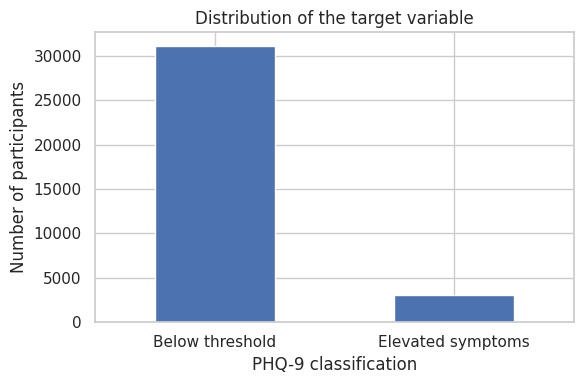

In [108]:
target_summary = (adult_data["target"].value_counts().sort_index()
                  .rename(index={0: "Below threshold", 1: "Elevated symptoms"})
                  .to_frame("Participants"))
target_summary["Percentage"] = (target_summary["Participants"] / target_summary["Participants"].sum() * 100).round(2)
display(target_summary)

target_summary["Participants"].plot(kind="bar", figsize=(6, 4))
plt.title("Distribution of the target variable")
plt.xlabel("PHQ-9 classification")
plt.ylabel("Number of participants")
plt.xticks(rotation=0)
save_fig("eda_target_distribution.png")

The target is imbalanced: approximately 91.15% of participants are below
the selected threshold, while 8.85% are classified as having elevated
depressive symptoms.

A model that predicts every participant as class 0 would achieve about
91.15% accuracy without identifying any positive cases. Therefore, recall,
precision, F1-score, ROC-AUC, and PR-AUC are important for evaluating the
models.

## Numerical features

I examine the distributions of age, family income-to-poverty ratio, and BMI.

Histograms help me identify skewed distributions and unusual values.
Summary statistics provide information about the typical values and spread
of each feature.

I also compare these features across the two target groups. These comparisons
help me understand the data and identify possible patterns for the models
to learn. They do not show that a feature causes elevated depressive
symptoms.

,RIDAGEYR,INDFMPIR,BMXBMI
count,34128.00,31253.00,33789.00
mean,49.62,2.53,29.27
std,17.81,1.62,7.00
min,20.00,0.00,13.18
25%,34.00,1.12,24.40
50%,49.00,2.13,28.10
75%,64.00,4.08,32.72
max,85.00,5.00,130.21


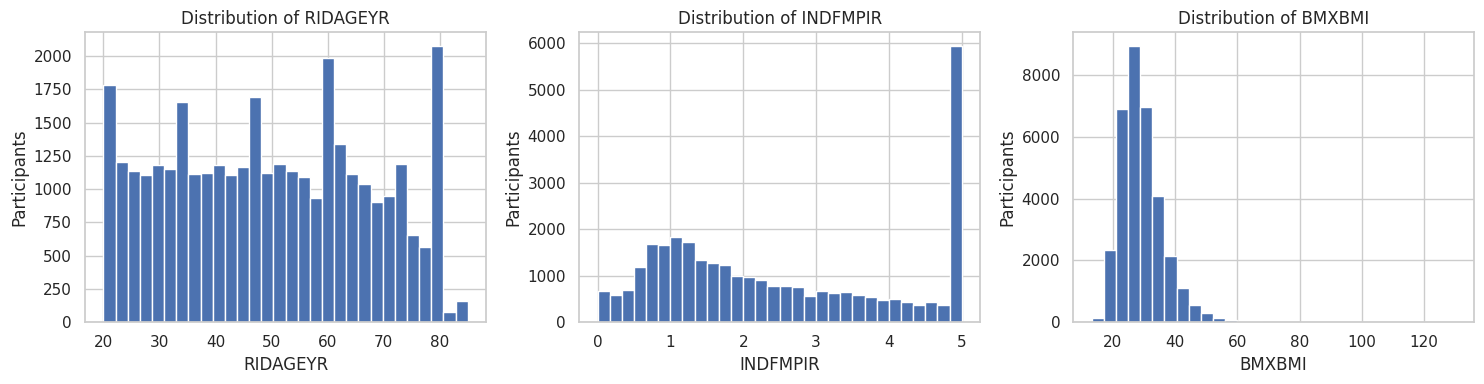

In [110]:
display(adult_data[NUMERIC_FEATURES].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, NUMERIC_FEATURES):
    adult_data[feature].hist(bins=30, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Participants")
save_fig("eda_numeric_distributions.png")

## Numerical features difference between the two groups


RIDAGEYR by target group (0 = below threshold, 1 = elevated):
        count   mean  median    std
target                             
0       31107  49.65    49.0  17.95
1        3021  49.22    50.0  16.29

INDFMPIR by target group (0 = below threshold, 1 = elevated):
        count  mean  median   std
target                           
0       28513  2.61    2.25  1.62
1        2740  1.71    1.24  1.37

BMXBMI by target group (0 = below threshold, 1 = elevated):
        count   mean  median   std
target                            
0       30814  29.10    28.0  6.83
1        2975  31.05    29.9  8.35


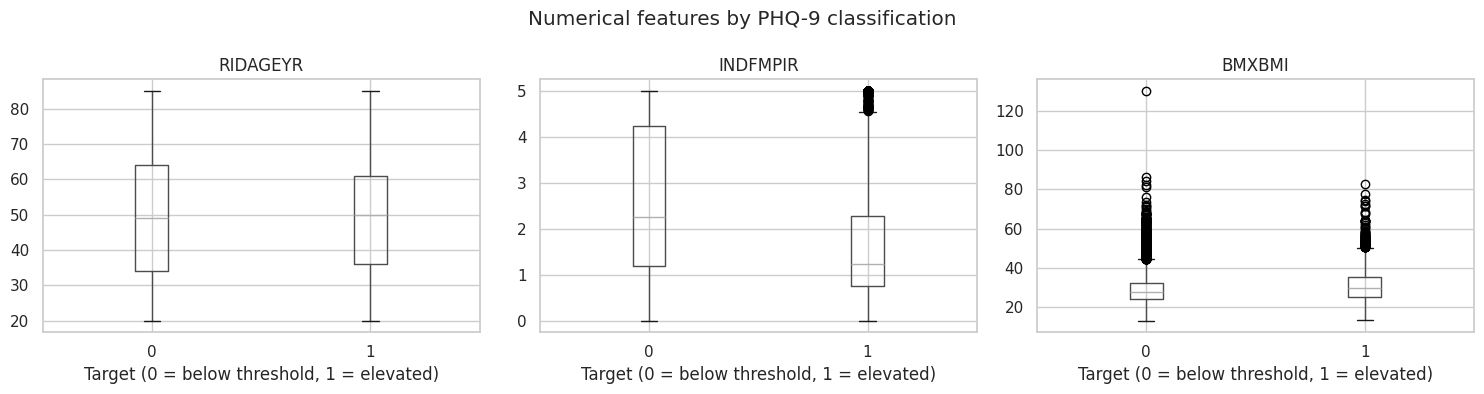

In [111]:
for feature in NUMERIC_FEATURES:
    print(f"\n{feature} by target group (0 = below threshold, 1 = elevated):")
    print(adult_data.groupby("target")[feature].agg(["count", "mean", "median", "std"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, NUMERIC_FEATURES):
    adult_data.boxplot(column=feature, by="target", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Target (0 = below threshold, 1 = elevated)")
plt.suptitle("Numerical features by PHQ-9 classification")
save_fig("eda_numeric_by_target.png")

## Categorical features

I compare the target distribution across the categories of sex, race/ethnicity,
education, and marital status.

This helps me see whether the proportion of participants above the selected
threshold varies between categories.

These results are descriptive. Differences between groups should not be
interpreted as causal relationships, and they do not automatically imply
that a feature will improve model predictions.

In [112]:
for feature in CATEGORICAL_FEATURES:
    print("=" * 55)
    print(f"{feature} by target group")
    counts = pd.crosstab(adult_data[feature], adult_data["target"])
    percentages = (pd.crosstab(adult_data[feature], adult_data["target"], normalize="index") * 100).round(2)
    display(pd.concat([counts, percentages], axis=1, keys=["Participants", "% within category"]))

RIAGENDR by target group


Participants       % within category       
target              0     1                 0      1
RIAGENDR                                            
1.0             15627  1102             93.41   6.59
2.0             15480  1919             88.97  11.03

RIDRETH1 by target group


Participants       % within category       
target              0     1                 0      1
RIDRETH1                                            
1.0              4881   461             91.37   8.63
2.0              2854   387             88.06  11.94
3.0             13327  1276             91.26   8.74
4.0              6662   674             90.81   9.19
5.0              3383   223             93.82   6.18

DMDEDUC2 by target group


Participants      % within category       
target              0    1                 0      1
DMDEDUC2                                           
1.0              2999  444             87.10  12.90
2.0              4186  637             86.79  13.21
3.0              7157  730             90.74   9.26
4.0              9234  902             91.10   8.90
5.0              7508  305             96.10   3.90

DMDMARTL by target group


Participants       % within category       
target              0     1                 0      1
DMDMARTL                                            
1.0             16494  1066             93.93   6.07
2.0              2402   292             89.16  10.84
3.0              3220   531             85.84  14.16
4.0               946   208             81.98  18.02
5.0              5520   625             89.83  10.17
6.0              2508   296             89.44  10.56

## Missing values in selected features

I count missing values in the selected predictors and calculate the
percentage missing for each feature.

This helps me decide how missing values should be handled. I use median
imputation for numerical features and most-frequent-category imputation
for categorical features. These imputation rules are learned from the
training set later in the notebook.

In [113]:
missing_summary = pd.DataFrame({
    "Missing_Count": adult_data[FEATURE_COLUMNS].isna().sum(),
    "Missing_Percentage": (adult_data[FEATURE_COLUMNS].isna().mean() * 100).round(2),
}).sort_values("Missing_Percentage", ascending=False)
display(missing_summary)

,Missing_Count,Missing_Percentage
INDFMPIR,2875,8.42
BMXBMI,339,0.99
DMDEDUC2,26,0.08
DMDMARTL,20,0.06
RIDAGEYR,0,0.00
RIDRETH1,0,0.00
RIAGENDR,0,0.00


## Problem stability across survey cycles

I calculate the proportion of participants classified as having elevated
symptoms in each survey cycle.

This allows me to inspect whether the target distribution is similar across
the years included in the dataset. If the proportions vary, a model trained
on a random mixture of cycles may not perform equally well on a future
cycle.

The current random split does not directly test future-cycle generalization.
A separate time-based evaluation would be needed for that purpose.

,Participants,Elevated_Symptoms,Prevalence
survey_cycle,,,
2005-2006,4284,268,6.26
2007-2008,5157,502,9.73
2009-2010,5281,504,9.54
2011-2012,4639,422,9.10
2013-2014,5054,490,9.70
2015-2016,4888,398,8.14
2017-2018,4825,437,9.06


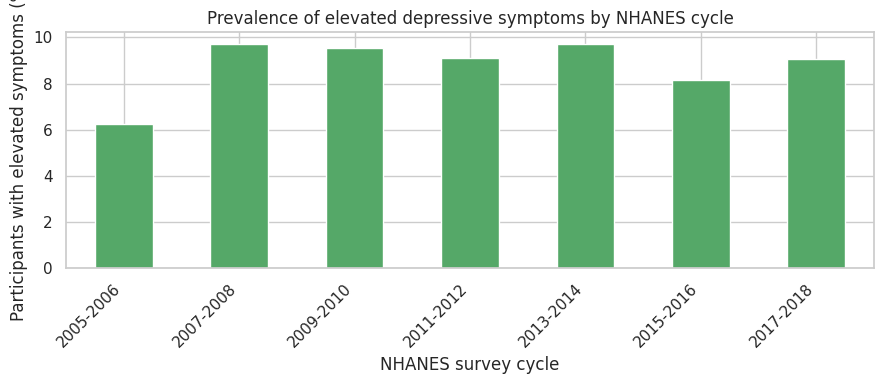

In [114]:
cycle_summary = (adult_data.groupby("survey_cycle")["target"]
                 .agg(Participants="count", Elevated_Symptoms="sum", Prevalence="mean"))
cycle_summary["Prevalence"] = (cycle_summary["Prevalence"] * 100).round(2)
display(cycle_summary)

cycle_summary["Prevalence"].plot(kind="bar", figsize=(9, 4), color="#55A868")
plt.title("Prevalence of elevated depressive symptoms by NHANES cycle")
plt.xlabel("NHANES survey cycle")
plt.ylabel("Participants with elevated symptoms (%)")
plt.xticks(rotation=45, ha="right")
save_fig("eda_prevalence_by_cycle.png")

# **6. Features, data splitting, preprocessing, and feature engineering**

## Build the feature matrix X and target Y

I separate the predictor variables from the target variable.

The input matrix X contains the seven selected demographic, socioeconomic,
and health-related features. The target y contains the binary classification
labels.

I exclude SEQN because it is a participant identifier, and I exclude the
PHQ-9 questionnaire items and total score because they were used to create
the target. Including those variables would cause target leakage and make
the evaluation misleading.

In [115]:
X = adult_data[FEATURE_COLUMNS].copy()
y = adult_data["target"].copy()

assert "SEQN" not in X.columns and "phq9_score" not in X.columns      # leakage / ID safety checks
assert not any(col in X.columns for col in PHQ9_COLS)

print("Feature matrix shape:", X.shape)
print("Target shape        :", y.shape)
print("\nTarget percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Feature matrix shape: (34128, 7)
Target shape        : (34128,)

Target percentages:
target
0    91.15
1     8.85
Name: proportion, dtype: float64


# Data splitting

I split the dataset into training, validation, and test sets using a
70/15/15 ratio.

The training set is used to fit the models. The validation set is used to
compare experiments and make model-selection decisions. The test set is
held back until the final evaluation.

I use stratified splitting so that each set has approximately the same
proportion of positive and negative cases. I also use a fixed random seed
to make the split reproducible.

In [116]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=VAL_SIZE / (1 - TEST_SIZE),
    random_state=SEED, stratify=y_train_val)

print("Training set  :", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set      :", X_test.shape)

print("\nPositive percentage in each split (should be nearly identical):")
for name, labels in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"  {name:<11}: {labels.mean() * 100:.2f}%")

Training set  : (23888, 7)
Validation set: (5120, 7)
Test set      : (5120, 7)

Positive percentage in each split (should be nearly identical):
  Training   : 8.85%
  Validation : 8.85%
  Test       : 8.85%


In [117]:
missing_by_split = pd.DataFrame({
    "Train": X_train.isna().sum(),
    "Validation": X_val.isna().sum(),
    "Test": X_test.isna().sum(),
})
print("Missing values per feature in each split:")
display(missing_by_split)

Missing values per feature in each split:


,Train,Validation,Test
RIDAGEYR,0,0,0
INDFMPIR,2006,428,441
BMXBMI,245,43,51
RIAGENDR,0,0,0
RIDRETH1,0,0,0
DMDEDUC2,18,6,2
DMDMARTL,16,1,3


## The preprocessing pipeline


The models require numerical input, but the original dataset contains both
numerical and categorical variables.

For numerical features, I use median imputation to fill missing values
and standardization to put the features on comparable scales. For
categorical features, I use the most frequent category to fill missing
values and one-hot encoding to represent categories as separate binary
columns.

I combine these operations using a ColumnTransformer. I fit the pipeline
on the training data only, then apply the learned transformations to the
validation and test data.

This is important because fitting the preprocessing steps on all the data
would allow information from the validation or test sets to influence the
training process.

In [118]:
def build_preprocessor(numeric_cols, categorical_cols):
    # One mini-pipeline per feature type, combined by a ColumnTransformer.
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),  # dense output: Keras needs dense arrays
    ])
    return ColumnTransformer([
        ("numerical", numeric_pipe, numeric_cols),
        ("categorical", categorical_pipe, categorical_cols),
    ])


# Baseline preprocessor: original features (continuous age)
preprocessor = build_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
X_train_processed = preprocessor.fit_transform(X_train)     # learn statistics from TRAIN only
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [119]:
print("Processed shapes  ->  train:", X_train_processed.shape,
      "| validation:", X_val_processed.shape, "| test:", X_test_processed.shape)

for name, array in [("train", X_train_processed), ("validation", X_val_processed), ("test", X_test_processed)]:
    print(f"Missing values remaining in {name}: {np.isnan(array).sum()}")

Processed shapes  ->  train: (23888, 21) | validation: (5120, 21) | test: (5120, 21)
Missing values remaining in train: 0
Missing values remaining in validation: 0
Missing values remaining in test: 0


## Feature engineering: Grouping age into decades

In this experiment, I replace continuous age with age categories.

The purpose is to test whether age groups capture useful patterns that
may be less apparent when age is represented as a single continuous
number. One-hot encoding then converts the age groups into model-ready
features.

I compare this experiment with the original-feature Logistic Regression
model while keeping the other settings the same. This makes it easier to
attribute performance differences to the change in age representation.

In [120]:
AGE_BINS = [19, 29, 39, 49, 59, 69, np.inf]
AGE_LABELS = ["20-29", "30-39", "40-49", "50-59", "60-69", "70+"]

def add_age_groups(frame):
    # Return a copy where continuous age is replaced by a decade group (as text categories).
    frame = frame.copy()
    frame["RIDAGEYR"] = pd.cut(frame["RIDAGEYR"], bins=AGE_BINS, labels=AGE_LABELS).astype(str)
    return frame

AGE_NUMERIC = ["INDFMPIR", "BMXBMI"]
AGE_CATEGORICAL = ["RIDAGEYR"] + CATEGORICAL_FEATURES

X_train_age = add_age_groups(X_train)
X_val_age = add_age_groups(X_val)
X_test_age = add_age_groups(X_test)

age_preprocessor = build_preprocessor(AGE_NUMERIC, AGE_CATEGORICAL)
X_train_age_processed = age_preprocessor.fit_transform(X_train_age)    # fit on TRAIN only
X_val_age_processed = age_preprocessor.transform(X_val_age)
X_test_age_processed = age_preprocessor.transform(X_test_age)

print("Age-group feature shapes -> train:", X_train_age_processed.shape,
      "| validation:", X_val_age_processed.shape, "| test:", X_test_age_processed.shape)
print("\nParticipants per age group in the training set:")
print(X_train_age["RIDAGEYR"].value_counts().reindex(AGE_LABELS))

Age-group feature shapes -> train: (23888, 26) | validation: (5120, 26) | test: (5120, 26)

Participants per age group in the training set:
RIDAGEYR
20-29    4058
30-39    3914
40-49    3954
50-59    3816
60-69    4184
70+      3962
Name: count, dtype: int64


## 7. Evaluation metrics and the experiment log

I define one function to calculate the main evaluation metrics for every
experiment. This avoids repeating the same metric calculations in each
model section and ensures that the models are evaluated consistently.

I record accuracy, precision, recall, specificity, F1-score, ROC-AUC,
and PR-AUC, along with the confusion-matrix counts.

I also record the experiment identifier, model settings, changes from the
previous experiment, and training time. This creates a structured record
of the experiments so that I can compare the models and explain why
particular changes were tested.

The experiment log contains validation results. Final test results are
recorded separately after model selection.

In [121]:
def compute_metrics(y_true, proba, threshold=0.5):
    # All metrics for one set of predicted probabilities at one decision threshold.
    y_true = np.asarray(y_true)
    pred = (np.asarray(proba) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),      # = sensitivity
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }


experiment_log = []     # one dictionary per experiment -> becomes the experiment table
registry = {}           # experiment id -> fitted model + data needed later
SPLIT_DESCRIPTION = "Stratified 70/15/15, seed 42 (metrics on validation)"


def log_experiment(exp_id, approach, model_name, change, settings, features_name,
                   model, kind, data, val_proba, preprocessor_obj, uses_age_groups,
                   train_seconds, history=None):
    # Record one experiment: metrics go to experiment_log, objects go to registry.
    metrics = compute_metrics(y_val, val_proba)
    experiment_log.append({
        "Experiment": exp_id, "Approach": approach, "Model": model_name,
        "Input_features": features_name, "Change_from_previous": change,
        "Settings": settings, "Split": SPLIT_DESCRIPTION,
        "Train_sec": round(train_seconds, 1), **metrics,
    })
    registry[exp_id] = {
        "model": model, "kind": kind, "name": model_name,
        "X_train": data[0], "X_val": data[1], "X_test": data[2],
        "val_proba": np.asarray(val_proba), "history": history,
        "preprocessor": preprocessor_obj, "uses_age_groups": uses_age_groups,
    }


def show_result(exp_id):
    # Print the validation metrics and confusion matrix of one experiment.
    row = next(r for r in experiment_log if r["Experiment"] == exp_id)
    keys = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC_AUC", "PR_AUC"]
    print(f"{exp_id} - {row['Model']}   (trained in {row['Train_sec']} s)")
    print(pd.Series({k: round(row[k], 4) for k in keys}).to_string())
    print("\nValidation confusion matrix  [[TN, FP], [FN, TP]]:")
    print(np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]]))


def predict_proba_any(entry, X):
    # Positive-class probabilities for either a scikit-learn model or a Keras model.
    if entry["kind"] == "sklearn":
        return entry["model"].predict_proba(X)[:, 1]
    return entry["model"].predict(make_dataset(X), verbose=0).ravel()

# **8. Traditional ML models**

In [122]:
def run_sklearn_experiment(exp_id, model_name, model, features_name, data, preprocessor_obj,
                           uses_age_groups, change, settings):
    # Train a scikit-learn model on the training set and log its validation results.
    X_tr, X_va, X_te = data
    start = time.perf_counter()
    model.fit(X_tr, y_train)                              # y_train is shared by all experiments
    seconds = time.perf_counter() - start

    val_proba = model.predict_proba(X_va)[:, 1]
    log_experiment(exp_id, "Traditional ML", model_name, change, settings, features_name,
                   model, "sklearn", data, val_proba, preprocessor_obj, uses_age_groups, seconds)
    show_result(exp_id)


BASE_DATA = (X_train_processed, X_val_processed, X_test_processed)          # continuous age
AGE_DATA = (X_train_age_processed, X_val_age_processed, X_test_age_processed)  # age groups

## Logistic Regression baseline

I start with Logistic Regression as a baseline model.

It provides a relatively simple approach for estimating the probability
of belonging to the positive class. I use balanced class weights because
the positive class represents only a small proportion of the dataset.

I set max_iter to 1000 to allow enough optimization iterations for the
model to converge.

This first experiment establishes a reference point for the more complex
models and later feature-engineering experiments.

In [123]:
run_sklearn_experiment(
    "E1", "Logistic Regression",
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Original features (21 cols)", BASE_DATA, preprocessor, False,
    change="Baseline", settings="max_iter=1000, class_weight=balanced, C=1.0")

E1 - Logistic Regression   (trained in 0.3 s)
Accuracy       0.6477
Precision      0.1538
Recall         0.6623
Specificity    0.6462
F1             0.2496
ROC_AUC        0.7170
PR_AUC         0.1839

Validation confusion matrix  [[TN, FP], [FN, TP]]:
[[3016 1651]
 [ 153  300]]


## Logistic regression with age groups

This experiment uses the same Logistic Regression settings as the baseline,
but replaces continuous age with age groups.

Keeping the model settings the same makes this a more direct comparison
of the feature-engineering change. I compare the validation metrics to see
whether grouping age improves positive-class identification and overall
classification performance.

In [124]:
run_sklearn_experiment(
    "E2", "Logistic Regression + age groups",
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Age grouped by decade (26 cols)", AGE_DATA, age_preprocessor, True,
    change="E1 + age grouped into decades", settings="max_iter=1000, class_weight=balanced, C=1.0")

E2 - Logistic Regression + age groups   (trained in 0.2 s)
Accuracy       0.6541
Precision      0.1557
Recall         0.6578
Specificity    0.6537
F1             0.2518
ROC_AUC        0.7229
PR_AUC         0.1979

Validation confusion matrix  [[TN, FP], [FN, TP]]:
[[3051 1616]
 [ 155  298]]


## Random forest baseline

I test Random Forest to investigate whether an ensemble of decision trees
can learn patterns that Logistic Regression may not capture.

The model uses 200 trees, a minimum leaf size of 5, and balanced class
weights. The minimum leaf size helps prevent individual trees from creating
leaves based on very few observations.

I compare the results with Logistic Regression to understand how the
different modeling approach affects accuracy, recall, precision, and the
ranking metrics.

In [125]:
run_sklearn_experiment(
    "E3", "Random Forest (baseline)",
    RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                           random_state=SEED, n_jobs=-1),
    "Original features (21 cols)", BASE_DATA, preprocessor, False,
    change="Different algorithm (trees instead of linear)",
    settings="n_estimators=200, min_samples_leaf=5, max_depth=None, class_weight=balanced")

E3 - Random Forest (baseline)   (trained in 8.3 s)
Accuracy       0.8648
Precision      0.2505
Recall         0.2649
Specificity    0.9231
F1             0.2575
ROC_AUC        0.7160
PR_AUC         0.1948

Validation confusion matrix  [[TN, FP], [FN, TP]]:
[[4308  359]
 [ 333  120]]


## Random forests(max depth = 15, leaf =2)

In this experiment, I change the maximum tree depth to 15 and reduce the
minimum leaf size from 5 to 2.

These changes allow the trees to form more detailed decision rules, but
they can also increase the risk of fitting patterns that do not generalize
well.

I compare the tuned model with the baseline rather than assuming that
greater model complexity will improve performance. A change is useful
only if the relevant evaluation metrics improve.

In [126]:
run_sklearn_experiment(
    "E4", "Random Forest (depth 15, leaf 2)",
    RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=2,
                           class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Original features (21 cols)", BASE_DATA, preprocessor, False,
    change="E3 with max_depth=15 and min_samples_leaf=2",
    settings="n_estimators=200, min_samples_leaf=2, max_depth=15, class_weight=balanced")

E4 - Random Forest (depth 15, leaf 2)   (trained in 10.7 s)
Accuracy       0.8795
Precision      0.2545
Recall         0.1876
Specificity    0.9466
F1             0.2160
ROC_AUC        0.7129
PR_AUC         0.1914

Validation confusion matrix  [[TN, FP], [FN, TP]]:
[[4418  249]
 [ 368   85]]


# **9. Deep learning models**

## Input pipeline

I use TensorFlow and Keras to build a feed-forward neural network.

The input pipeline converts the preprocessed features into float32 arrays,
groups observations into batches, and prefetches data to support efficient
training. During training, the training examples are shuffled to reduce
dependence on their original order.

I use the same training and validation split as the traditional models
so that the comparison is based on the same observations.

In [127]:
BATCH_SIZE = 32
MAX_EPOCHS = 50
PATIENCE = 5
LEARNING_RATE = 1e-3


def make_dataset(X, y=None, training=False):
    # Build a tf.data pipeline: slices -> (shuffle) -> batch -> prefetch.
    if hasattr(X, "toarray"):                       # safety: convert sparse -> dense
        X = X.toarray()
    X = np.asarray(X, dtype="float32")
    if y is None:                                   # features only (used for prediction)
        dataset = tf.data.Dataset.from_tensor_slices(X)
    else:
        dataset = tf.data.Dataset.from_tensor_slices((X, np.asarray(y, dtype="float32")))
    if training:
        dataset = dataset.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def build_model(input_dim, hidden_units=(32, 16), dropout_rates=(0.3, 0.2), learning_rate=LEARNING_RATE):
    # Sequential API model: [Dense -> Dropout] x N, then a single sigmoid output.
    model = keras.Sequential([keras.layers.Input(shape=(input_dim,))])
    for units, rate in zip(hidden_units, dropout_rates):
        model.add(keras.layers.Dense(units, activation="relu"))
        model.add(keras.layers.Dropout(rate))
    model.add(keras.layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.AUC(name="auc")],
    )
    return model

## Training helper

The network contains two hidden layers with 32 and 16 units. ReLU activation
functions allow the network to learn nonlinear relationships. Dropout
layers randomly deactivate some hidden units during training to help
reduce overfitting.

The final layer contains one unit with a sigmoid activation function,
which produces a probability between 0 and 1 for the positive class.

I use binary cross-entropy as the loss function because this is a binary
classification problem. Adam is used to update the network's weights during
training.

In [128]:
def run_dl_experiment(exp_id, model_name, hidden_units, dropout_rates, class_weight, change):
    keras.utils.set_random_seed(SEED)                       # same seed -> repeatable initial weights
    model = build_model(X_train_processed.shape[1], hidden_units, dropout_rates)

    train_ds = make_dataset(X_train_processed, y_train, training=True)
    val_ds = make_dataset(X_val_processed, y_val)

    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, exp_id)),
    ]

    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
                        class_weight=class_weight, callbacks=callbacks, verbose=0)
    seconds = time.perf_counter() - start

    val_proba = model.predict(make_dataset(X_val_processed), verbose=0).ravel()

    settings = (f"hidden={hidden_units}, dropout={dropout_rates}, Adam lr={LEARNING_RATE}, "
                f"batch={BATCH_SIZE}, early_stop(patience={PATIENCE}), "
                f"class_weight={'balanced' if class_weight else 'none'}")
    log_experiment(exp_id, "Deep learning", model_name, change, settings, "Original features (21 cols)",
                   model, "keras", BASE_DATA, val_proba, preprocessor, False, seconds, history=history.history)

    history_df = pd.DataFrame(history.history)
    history_df.index = history_df.index + 1                 # epochs start at 1
    history_df.index.name = "epoch"
    history_df.to_csv(os.path.join(TABLE_DIR, f"{exp_id}_history.csv"))

    print(f"Trained for {len(history_df)} epochs (best weights restored).")
    show_result(exp_id)

The positive class is much smaller than the negative class. During training,
a model may therefore minimize its loss by favoring the majority class.

I calculate balanced class weights from the training labels only. This
gives the minority class a larger weight when the loss is calculated,
making mistakes on positive cases more influential during training.

Class weighting does not add new observations or guarantee better
performance. I compare the weighted and unweighted networks to determine
how the change affects recall, precision, and the other metrics.

In [129]:
# Class weights computed from the TRAINING labels only: weight = n_samples / (n_classes * n_in_class)
classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

Class weights: {0: 0.5485693289854406, 1: 5.647281323877069}


## Baseline network(no class weight)

I first train the neural network without class weights. This establishes
how the architecture behaves before explicitly addressing the class
imbalance.

I use early stopping to monitor validation loss. If validation loss stops
improving for five epochs, training stops and the weights from the best
epoch are restored. This avoids automatically using the weights from the
last epoch.

I then train the same architecture with balanced class weights. Keeping
the architecture and main settings unchanged makes it easier to understand
the effect of class weighting.

In [130]:
run_dl_experiment("E5", "Neural network (unweighted)", (32, 16), (0.3, 0.2),
                  class_weight=None, change="Baseline neural network")

Trained for 19 epochs (best weights restored).
E5 - Neural network (unweighted)   (trained in 100.8 s)
Accuracy       0.9115
Precision      0.0000
Recall         0.0000
Specificity    1.0000
F1             0.0000
ROC_AUC        0.7359
PR_AUC         0.2100

Validation confusion matrix  [[TN, FP], [FN, TP]]:
[[4667    0]
 [ 453    0]]


## Same network with class weight

In [131]:
run_dl_experiment("E6", "Neural network (class-weighted)", (32, 16), (0.3, 0.2),
                  class_weight=class_weights, change="E5 + balanced class weights")

Trained for 26 epochs (best weights restored).
E6 - Neural network (class-weighted)   (trained in 122.7 s)
Accuracy       0.7191
Precision      0.1758
Recall         0.5894
Specificity    0.7317
F1             0.2708
ROC_AUC        0.7296
PR_AUC         0.2055

Validation confusion matrix  [[TN, FP], [FN, TP]]:
[[3415 1252]
 [ 186  267]]


## Larger network

I increase the hidden-layer sizes from 32 and 16 units to 64 and 32 units,
while retaining the dropout settings and class weighting.

The purpose is to test whether a network with more hidden units can learn
more useful patterns from the same input features.

A larger network also has more parameters, so it may require more training
and can overfit. I use the validation metrics and learning curves to
determine whether the added complexity provides a meaningful improvement.

In [132]:
run_dl_experiment("E7", "Neural network (larger, class-weighted)", (64, 32), (0.3, 0.2),
                  class_weight=class_weights, change="E6 with 64 -> 32 hidden units")

Trained for 13 epochs (best weights restored).
E7 - Neural network (larger, class-weighted)   (trained in 54.1 s)
Accuracy       0.6918
Precision      0.1747
Recall         0.6667
Specificity    0.6942
F1             0.2768
ROC_AUC        0.7353
PR_AUC         0.2053

Validation confusion matrix  [[TN, FP], [FN, TP]]:
[[3240 1427]
 [ 151  302]]


In [133]:
# Architecture summary of the class-weighted network (E6)
registry["E6"]["model"].summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 32)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,749 (14.65 KB)

 Trainable params: 1,249 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,500 (9.77 KB)

# **10. Decision threshold analysis**

The neural network produces probabilities, which must be converted into
class predictions using a decision threshold.

At a threshold of 0.5, probabilities of 0.5 or higher are classified as
positive. Lowering the threshold generally identifies more positive cases,
but it can also increase the number of false positives.

I compare several thresholds using the validation predictions. This helps
me understand the trade-off between precision, recall, specificity, and
F1-score.

I use validation data for this analysis because the test set must remain
separate from model-selection decisions. The threshold used for final
testing should be selected before inspecting the final test results.

In [134]:
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
e6_val_proba = registry["E6"]["val_proba"]

threshold_df = pd.DataFrame([{"Threshold": t, **compute_metrics(y_val, e6_val_proba, threshold=t)} for t in THRESHOLDS])
display(threshold_df[["Threshold", "Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC_AUC", "PR_AUC"]].round(4))
threshold_df.to_csv(os.path.join(TABLE_DIR, "E8_threshold_analysis_validation.csv"), index=False)

,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,PR_AUC
0,0.3,0.3842,0.1173,0.9139,0.3328,0.2080,0.7296,0.2055
1,0.4,0.5469,0.1378,0.7837,0.5239,0.2343,0.7296,0.2055
2,0.5,0.7191,0.1758,0.5894,0.7317,0.2708,0.7296,0.2055
3,0.6,0.8256,0.2222,0.3885,0.8680,0.2827,0.7296,0.2055
4,0.7,0.8852,0.2742,0.1810,0.9535,0.2181,0.7296,0.2055


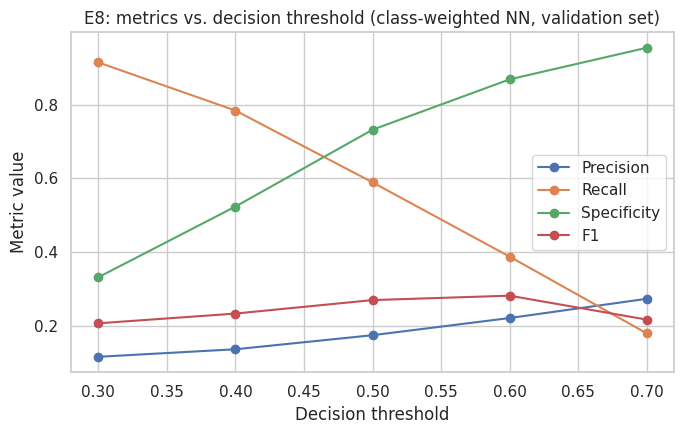

In [135]:
plt.figure(figsize=(7, 4.5))
for metric in ["Precision", "Recall", "Specificity", "F1"]:
    plt.plot(threshold_df["Threshold"], threshold_df[metric], marker="o", label=metric)
plt.xlabel("Decision threshold")
plt.ylabel("Metric value")
plt.title("E8: metrics vs. decision threshold (class-weighted NN, validation set)")
plt.legend()
save_fig("e8_threshold_tradeoff.png")

# **11. Consolidated experiment table and model selection**

## Experiment table (validation set)

I combine the validation metrics from all experiments into one table.
The table records each model's settings, the change being tested, training
time, and validation performance.

This allows me to compare the experiments systematically instead of
choosing a model based on accuracy alone.

I consider the positive-class precision, recall, F1-score, ROC-AUC, and
PR-AUC when selecting the finalists. I also consider the intended use of
the model, because a model with high recall may still produce many false
positives.

The validation results are used for model selection. I do not use the
test results to decide which model or threshold to choose.

In [136]:
experiment_df = pd.DataFrame(experiment_log)
experiment_df.to_csv(os.path.join(TABLE_DIR, "experiment_results_validation_full.csv"), index=False)

compact_cols = ["Experiment", "Approach", "Model", "Change_from_previous",
                "Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC_AUC", "PR_AUC", "Train_sec"]
display(experiment_df[compact_cols].round(4))

,Experiment,Approach,Model,Change_from_previous,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,PR_AUC,Train_sec
0,E1,Traditional ML,Logistic Regression,Baseline,0.6477,0.1538,0.6623,0.6462,0.2496,0.7170,0.1839,0.3
1,E2,Traditional ML,Logistic Regression + age groups,E1 + age grouped into decades,0.6541,0.1557,0.6578,0.6537,0.2518,0.7229,0.1979,0.2
2,E3,Traditional ML,Random Forest (baseline),Different algorithm (trees instead of linear),0.8648,0.2505,0.2649,0.9231,0.2575,0.7160,0.1948,8.3
3,E4,Traditional ML,"Random Forest (depth 15, leaf 2)",E3 with max_depth=15 and min_samples_leaf=2,0.8795,0.2545,0.1876,0.9466,0.2160,0.7129,0.1914,10.7
4,E5,Deep learning,Neural network (unweighted),Baseline neural network,0.9115,0.0000,0.0000,1.0000,0.0000,0.7359,0.2100,100.8
5,E6,Deep learning,Neural network (class-weighted),E5 + balanced class weights,0.7191,0.1758,0.5894,0.7317,0.2708,0.7296,0.2055,122.7
6,E7,Deep learning,"Neural network (larger, class-weighted)",E6 with 64 -> 32 hidden units,0.6918,0.1747,0.6667,0.6942,0.2768,0.7353,0.2053,54.1


In [137]:
# Full settings for every run (for reproducibility / the report appendix)
for _, row in experiment_df.iterrows():
    print(f"{row['Experiment']}: {row['Model']}\n     features: {row['Input_features']}\n     settings: {row['Settings']}\n")

E1: Logistic Regression
     features: Original features (21 cols)
     settings: max_iter=1000, class_weight=balanced, C=1.0

E2: Logistic Regression + age groups
     features: Age grouped by decade (26 cols)
     settings: max_iter=1000, class_weight=balanced, C=1.0

E3: Random Forest (baseline)
     features: Original features (21 cols)
     settings: n_estimators=200, min_samples_leaf=5, max_depth=None, class_weight=balanced

E4: Random Forest (depth 15, leaf 2)
     features: Original features (21 cols)
     settings: n_estimators=200, min_samples_leaf=2, max_depth=15, class_weight=balanced

E5: Neural network (unweighted)
     features: Original features (21 cols)
     settings: hidden=(32, 16), dropout=(0.3, 0.2), Adam lr=0.001, batch=32, early_stop(patience=5), class_weight=none

E6: Neural network (class-weighted)
     features: Original features (21 cols)
     settings: hidden=(32, 16), dropout=(0.3, 0.2), Adam lr=0.001, batch=32, early_stop(patience=5), class_weight=balance

## Selecting the best model

In [138]:
val_table = experiment_df.set_index("Experiment")
trad_ids = val_table.index[val_table["Approach"] == "Traditional ML"].tolist()
dl_ids = val_table.index[val_table["Approach"] == "Deep learning"].tolist()
rf_ids = [e for e in trad_ids if "Random Forest" in val_table.loc[e, "Model"]]

best_trad_id = val_table.loc[trad_ids, "F1"].idxmax()
best_dl_id = val_table.loc[dl_ids, "F1"].idxmax()
best_rf_id = val_table.loc[rf_ids, "F1"].idxmax()

print(f"Best traditional model (validation F1): {best_trad_id} - {val_table.loc[best_trad_id, 'Model']}")
print(f"Best deep-learning model (validation F1): {best_dl_id} - {val_table.loc[best_dl_id, 'Model']}")
print(f"Best Random Forest (validation F1): {best_rf_id} - {val_table.loc[best_rf_id, 'Model']}")

FINALISTS = list(dict.fromkeys([best_trad_id, best_rf_id, best_dl_id]))   # unique, keeps order
print("\nFinalists evaluated on the test set:", FINALISTS)

Best traditional model (validation F1): E3 - Random Forest (baseline)
Best deep-learning model (validation F1): E7 - Neural network (larger, class-weighted)
Best Random Forest (validation F1): E3 - Random Forest (baseline)

Finalists evaluated on the test set: ['E3', 'E7']


# **12. Final evaluation on the test set**

After selecting the finalist models using validation results, I evaluate
them on the held-out test set.

The test set was not used to fit the models or choose the final model
settings. It provides a final assessment of how the selected models perform
on observations they did not use during training.

I report the same metrics used during validation and inspect the
classification reports and confusion matrices. I pay particular attention
to false negatives and false positives because these errors have different
consequences in a mental-health-related classification task.

The test results are used to compare the selected models, not to continue
tuning them.

In [139]:
test_rows = []
for exp_id in FINALISTS:
    entry = registry[exp_id]
    entry["test_proba"] = predict_proba_any(entry, entry["X_test"])
    test_rows.append({"Experiment": exp_id, "Model": entry["name"], "Threshold": 0.5,
                      **compute_metrics(y_test, entry["test_proba"])})

test_df = pd.DataFrame(test_rows)
test_df.to_csv(os.path.join(TABLE_DIR, "final_test_results.csv"), index=False)
display(test_df[["Experiment", "Model", "Threshold", "Accuracy", "Precision", "Recall",
                 "Specificity", "F1", "ROC_AUC", "PR_AUC"]].round(4))

,Experiment,Model,Threshold,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,PR_AUC
0,E3,Random Forest (baseline),0.5,0.8641,0.2398,0.2472,0.9239,0.2435,0.6981,0.1800
1,E7,"Neural network (larger, class-weighted)",0.5,0.6889,0.1678,0.6358,0.6940,0.2656,0.7218,0.1992


In [140]:
for exp_id in FINALISTS:
    entry = registry[exp_id]
    pred = (entry["test_proba"] >= 0.5).astype(int)
    print("=" * 70)
    print(f"{exp_id} - {entry['name']}  (test set)")
    print(classification_report(y_test, pred, target_names=TARGET_NAMES, zero_division=0))

E3 - Random Forest (baseline)  (test set)
                      precision    recall  f1-score   support

No elevated symptoms       0.93      0.92      0.93      4667
   Elevated symptoms       0.24      0.25      0.24       453

            accuracy                           0.86      5120
           macro avg       0.58      0.59      0.58      5120
        weighted avg       0.87      0.86      0.86      5120

E7 - Neural network (larger, class-weighted)  (test set)
                      precision    recall  f1-score   support

No elevated symptoms       0.95      0.69      0.80      4667
   Elevated symptoms       0.17      0.64      0.27       453

            accuracy                           0.69      5120
           macro avg       0.56      0.66      0.53      5120
        weighted avg       0.88      0.69      0.76      5120



## Confusion matrices

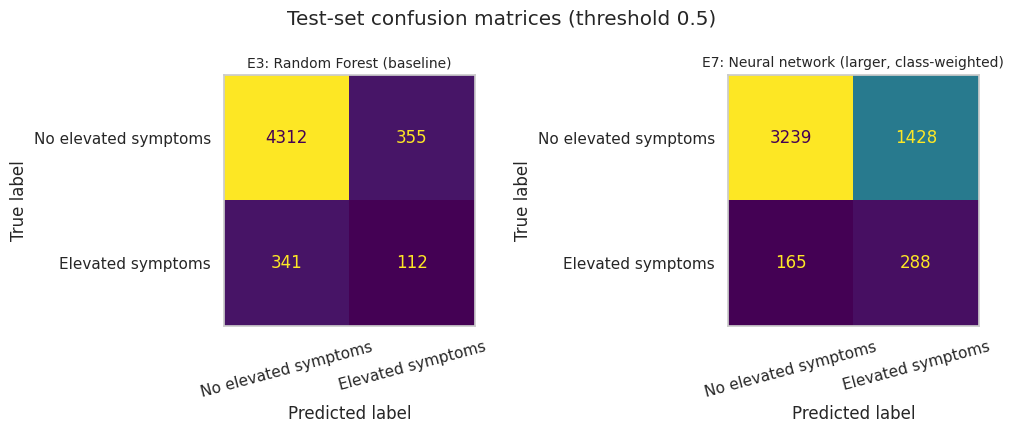

In [141]:
fig, axes = plt.subplots(1, len(FINALISTS), figsize=(5.2 * len(FINALISTS), 4.4))
axes = np.atleast_1d(axes)
for ax, exp_id in zip(axes, FINALISTS):
    entry = registry[exp_id]
    pred = (entry["test_proba"] >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=TARGET_NAMES,
                                            values_format="d", colorbar=False, ax=ax)
    ax.set_title(f"{exp_id}: {entry['name']}", fontsize=10)
    ax.grid(False)                       # the seaborn theme's grid lines would cross the matrix cells
    ax.tick_params(axis="x", rotation=15)
plt.suptitle("Test-set confusion matrices (threshold 0.5)")
save_fig("test_confusion_matrices.png")

## ROC curves and precision-recall curves

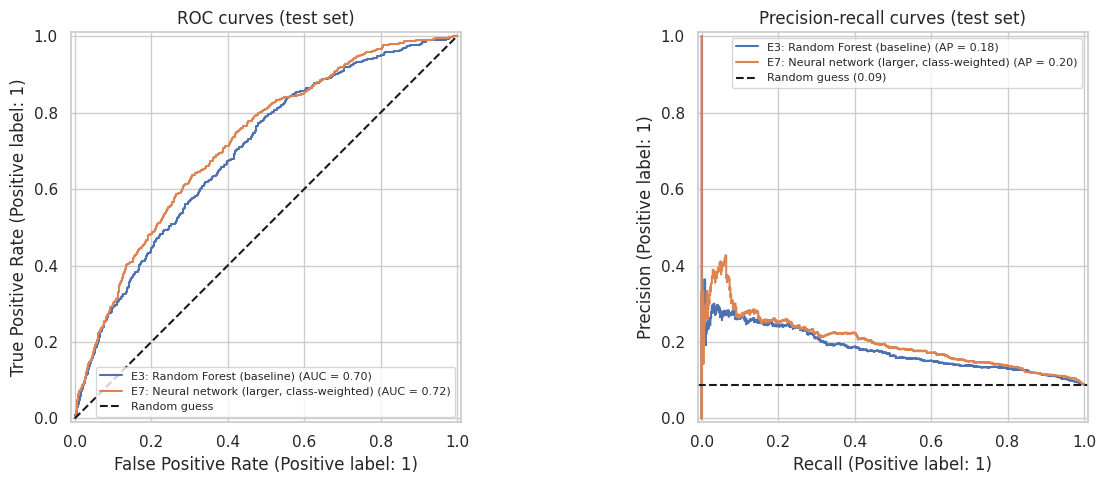

In [142]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for exp_id in FINALISTS:
    entry = registry[exp_id]
    RocCurveDisplay.from_predictions(y_test, entry["test_proba"], name=f"{exp_id}: {entry['name']}", ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, entry["test_proba"], name=f"{exp_id}: {entry['name']}", ax=axes[1])

axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC curves (test set)")
axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"Random guess ({y_test.mean():.2f})")
axes[1].set_title("Precision-recall curves (test set)")
axes[1].legend(fontsize=8)
save_fig("test_roc_and_pr_curves.png")

### Comparison

In [143]:
compare = []
for exp_id in FINALISTS:
    v = val_table.loc[exp_id]
    t = test_df.set_index("Experiment").loc[exp_id]
    compare.append({"Experiment": exp_id, "Model": registry[exp_id]["name"],
                    "Val_F1": v["F1"], "Test_F1": t["F1"],
                    "Val_ROC_AUC": v["ROC_AUC"], "Test_ROC_AUC": t["ROC_AUC"],
                    "Val_Recall": v["Recall"], "Test_Recall": t["Recall"]})
display(pd.DataFrame(compare).round(4))

,Experiment,Model,Val_F1,Test_F1,Val_ROC_AUC,Test_ROC_AUC,Val_Recall,Test_Recall
0,E3,Random Forest (baseline),0.2575,0.2435,0.7160,0.6981,0.2649,0.2472
1,E7,"Neural network (larger, class-weighted)",0.2768,0.2656,0.7353,0.7218,0.6667,0.6358


# **14. Learning curves and bias-variance diagnosis**

Learning curves help me understand how model performance changes during
training and whether there are signs of overfitting.

For the neural network, I compare training loss with validation loss and
training ROC-AUC with validation ROC-AUC across epochs. If training
performance continues to improve while validation performance worsens,
this may indicate overfitting.

For the traditional model, the learning curve examines how training and
cross-validated performance change as more training examples are used.

These plots provide evidence about model behavior, but they should be
interpreted alongside the final evaluation metrics rather than used alone
to decide which model is best.

## Neural network learning curves

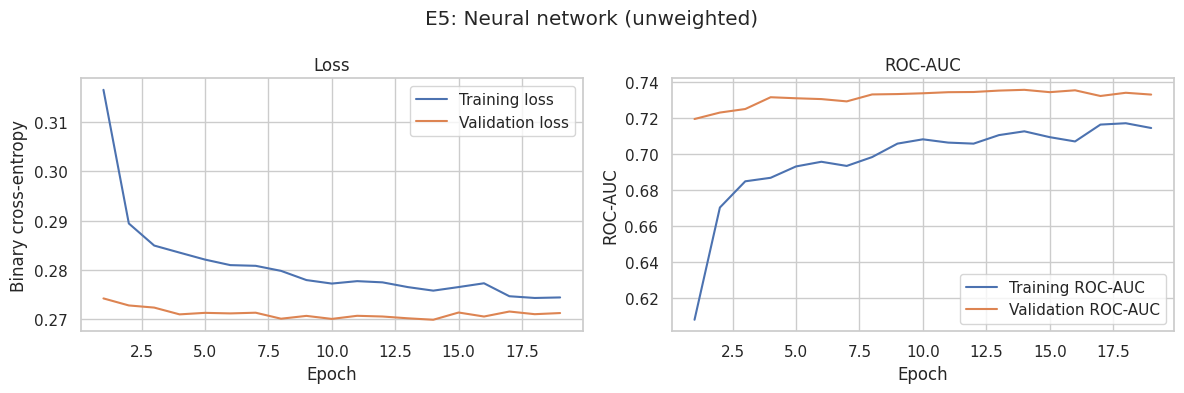

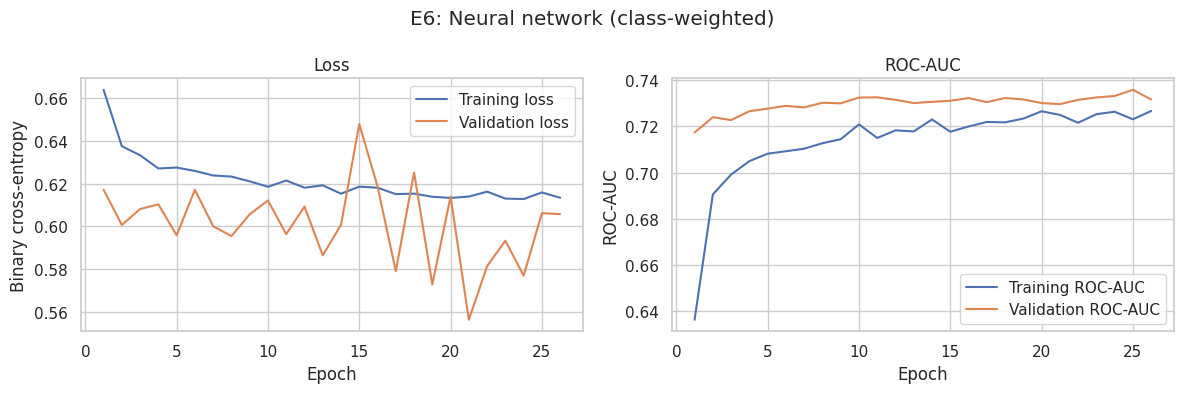

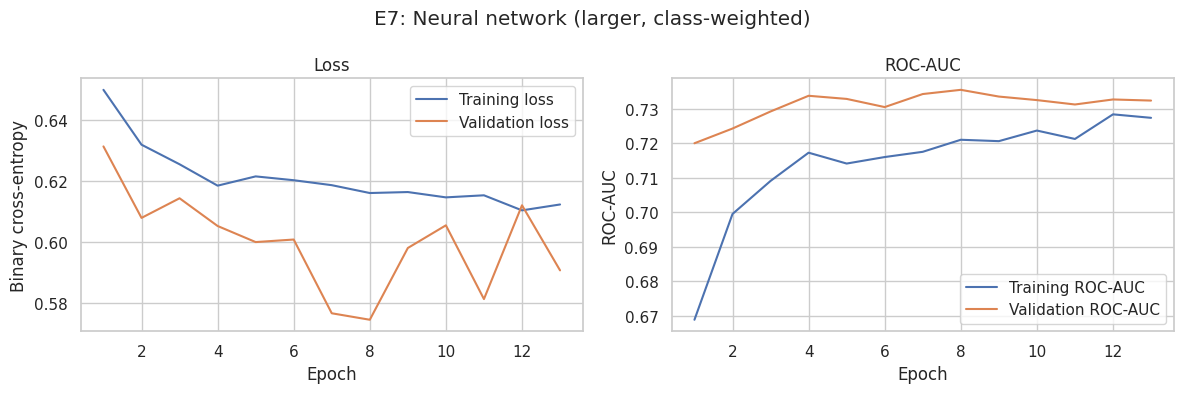

In [144]:
def plot_learning_curves(exp_id):
    # Training vs validation loss and ROC-AUC for one neural-network experiment.
    history = registry[exp_id]["history"]
    epochs = range(1, len(history["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Binary cross-entropy"); axes[0].set_title("Loss"); axes[0].legend()

    axes[1].plot(epochs, history["auc"], label="Training ROC-AUC")
    axes[1].plot(epochs, history["val_auc"], label="Validation ROC-AUC")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("ROC-AUC"); axes[1].set_title("ROC-AUC"); axes[1].legend()

    plt.suptitle(f"{exp_id}: {registry[exp_id]['name']}")
    save_fig(f"learning_curve_{exp_id}.png")

for exp_id in dl_ids:
    plot_learning_curves(exp_id)

## Traditional model learning curve(best)

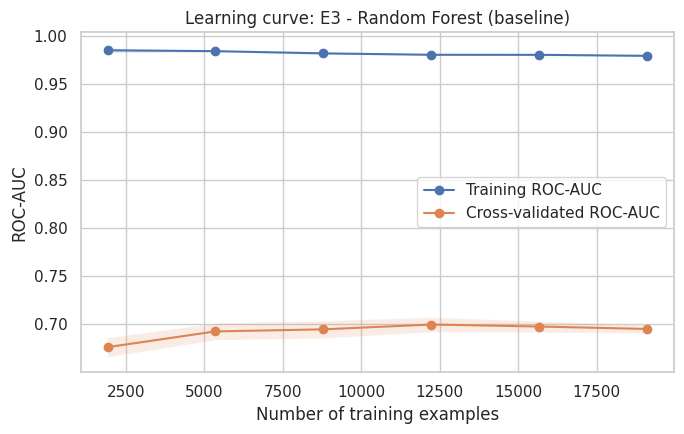

In [145]:
best_trad_entry = registry[best_trad_id]
train_sizes, train_scores, cv_scores = learning_curve(
    clone(best_trad_entry["model"]), best_trad_entry["X_train"], y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    train_sizes=np.linspace(0.1, 1.0, 6), scoring="roc_auc", n_jobs=-1)

plt.figure(figsize=(7, 4.5))
for scores, label in [(train_scores, "Training ROC-AUC"), (cv_scores, "Cross-validated ROC-AUC")]:
    plt.plot(train_sizes, scores.mean(axis=1), marker="o", label=label)
    plt.fill_between(train_sizes, scores.mean(axis=1) - scores.std(axis=1),
                     scores.mean(axis=1) + scores.std(axis=1), alpha=0.15)
plt.xlabel("Number of training examples")
plt.ylabel("ROC-AUC")
plt.title(f"Learning curve: {best_trad_id} - {best_trad_entry['name']}")
plt.legend()
save_fig("learning_curve_best_traditional.png")

## Training vs validation ROC-AUC

,Experiment,Model,Train_ROC_AUC,Val_ROC_AUC,Gap
0,E1,Logistic Regression,0.7068,0.7170,-0.0102
1,E2,Logistic Regression + age groups,0.7154,0.7229,-0.0075
2,E3,Random Forest (baseline),0.9782,0.7160,0.2622
3,E4,"Random Forest (depth 15, leaf 2)",0.9883,0.7129,0.2753
4,E5,Neural network (unweighted),0.7321,0.7359,-0.0038
5,E6,Neural network (class-weighted),0.7404,0.7296,0.0108
6,E7,"Neural network (larger, class-weighted)",0.7336,0.7353,-0.0017


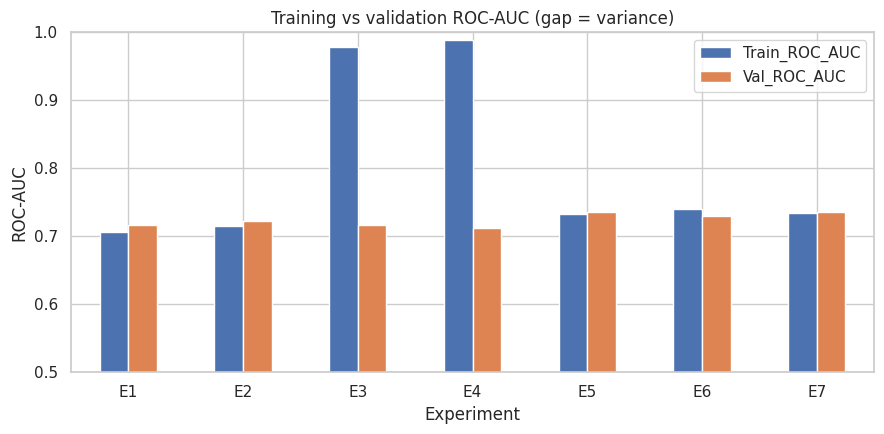

In [146]:
gap_rows = []
for exp_id, entry in registry.items():
    train_auc = roc_auc_score(y_train, predict_proba_any(entry, entry["X_train"]))
    val_auc = roc_auc_score(y_val, entry["val_proba"])
    gap_rows.append({"Experiment": exp_id, "Model": entry["name"],
                     "Train_ROC_AUC": train_auc, "Val_ROC_AUC": val_auc, "Gap": train_auc - val_auc})

gap_df = pd.DataFrame(gap_rows)
gap_df.to_csv(os.path.join(TABLE_DIR, "bias_variance_gap.csv"), index=False)
display(gap_df.round(4))

gap_df.set_index("Experiment")[["Train_ROC_AUC", "Val_ROC_AUC"]].plot(kind="bar", figsize=(9, 4.5))
plt.ylabel("ROC-AUC"); plt.ylim(0.5, 1.0); plt.xticks(rotation=0)
plt.title("Training vs validation ROC-AUC (gap = variance)")
save_fig("bias_variance_gap.png")

# **15. Error analysis**

The confusion matrix separates predictions into true negatives, false
positives, false negatives, and true positives.

False negatives are participants whose scores meet the elevated-symptoms
threshold but whom the model classifies as negative. False positives are
participants below the threshold whom the model classifies as positive.

The ROC curve shows the trade-off between sensitivity and false-positive
rate across thresholds. The precision-recall curve focuses on the positive
class and is especially useful when the classes are imbalanced.

I use these analyses to explain the types of errors each model makes,
rather than relying only on a single summary score.

,False positives,False negatives
Model,,
Random Forest (baseline),355,341
"Neural network (larger, class-weighted)",1428,165


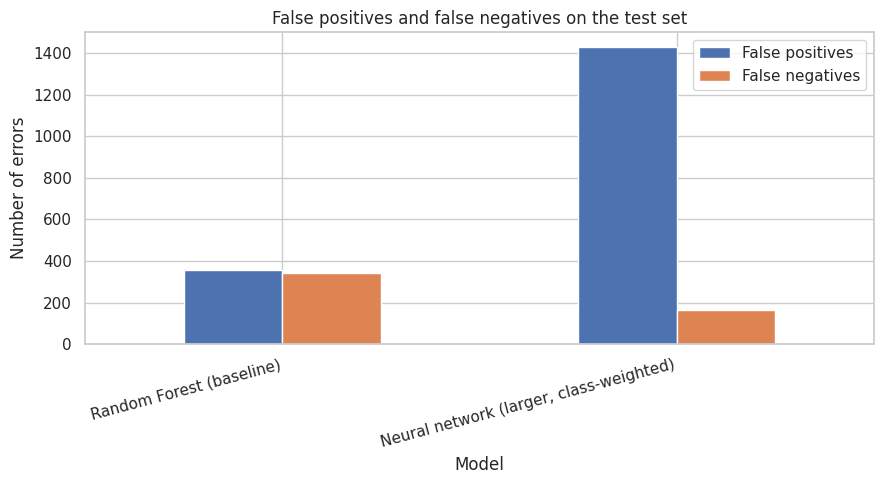

In [147]:
errors_df = test_df.set_index("Model")[["FP", "FN"]].rename(columns={"FP": "False positives", "FN": "False negatives"})
display(errors_df)

errors_df.plot(kind="bar", figsize=(9, 5))
plt.title("False positives and false negatives on the test set")
plt.xlabel("Model"); plt.ylabel("Number of errors")
plt.xticks(rotation=15, ha="right")
save_fig("test_error_comparison.png")16

## Subgroup error analysis

I compare model performance across selected demographic and data-availability
groups.

The purpose is to check whether the model's recall, precision, and
specificity differ substantially across groups. Such differences may
indicate that the model does not perform equally well for all participants.

These comparisons are exploratory and do not prove that a model is fair
or unfair. Group sizes and uncertainty should also be considered, and
demographic features require particular care in any real-world mental
health application.

In [148]:
def subgroup_report(frame, group_col):
    # Per-subgroup error rates for one grouping column.
    rows = []
    for group, sub in frame.groupby(group_col, observed=True):
        tp = int(((sub["y_true"] == 1) & (sub["pred"] == 1)).sum())
        fn = int(((sub["y_true"] == 1) & (sub["pred"] == 0)).sum())
        fp = int(((sub["y_true"] == 0) & (sub["pred"] == 1)).sum())
        tn = int(((sub["y_true"] == 0) & (sub["pred"] == 0)).sum())
        rows.append({group_col: group, "n": len(sub), "Prevalence": sub["y_true"].mean(),
                     "Recall": tp / (tp + fn) if (tp + fn) else np.nan,
                     "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
                     "Precision": tp / (tp + fp) if (tp + fp) else np.nan,
                     "False_negatives": fn, "False_positives": fp})
    return pd.DataFrame(rows)


best_dl_entry = registry[best_dl_id]
error_frame = X_test.copy()
error_frame["y_true"] = y_test.values                                   # same row order as X_test
error_frame["pred"] = (best_dl_entry["test_proba"] >= 0.5).astype(int)
error_frame["sex"] = error_frame["RIAGENDR"].map({1.0: "Male", 2.0: "Female"})
error_frame["age_group"] = pd.cut(error_frame["RIDAGEYR"], bins=AGE_BINS, labels=AGE_LABELS)
error_frame["income_missing"] = error_frame["INDFMPIR"].isna().map({True: "Income missing", False: "Income reported"})

print(f"Subgroup analysis for {best_dl_id} - {best_dl_entry['name']} (test set, threshold 0.5)")
subgroup_tables = []
for column in ["sex", "age_group", "income_missing"]:
    table = subgroup_report(error_frame, column)
    display(table.round(3))
    subgroup_tables.append(table.rename(columns={column: "Group"}).assign(Grouping=column))

pd.concat(subgroup_tables).to_csv(os.path.join(TABLE_DIR, "subgroup_error_analysis.csv"), index=False)

Subgroup analysis for E7 - Neural network (larger, class-weighted) (test set, threshold 0.5)


,sex,n,Prevalence,Recall,Specificity,Precision,False_negatives,False_positives
0,Female,2655,0.105,0.771,0.565,0.172,64,1034
1,Male,2465,0.071,0.420,0.828,0.156,101,394


,age_group,n,Prevalence,Recall,Specificity,Precision,False_negatives,False_positives
0,20-29,900,0.082,0.486,0.689,0.123,38,257
1,30-39,872,0.089,0.692,0.678,0.174,24,256
2,40-49,810,0.094,0.816,0.674,0.206,14,239
3,50-59,797,0.120,0.719,0.599,0.197,27,281
4,60-69,882,0.086,0.618,0.677,0.153,29,260
5,70+,859,0.062,0.377,0.833,0.129,33,135


,income_missing,n,Prevalence,Recall,Specificity,Precision,False_negatives,False_positives
0,Income missing,441,0.107,0.596,0.706,0.194,19,116
1,Income reported,4679,0.087,0.640,0.693,0.165,146,1312


# **16. Saving the best models and reproducibility**

I save the selected models and their preprocessing objects so that the
same transformations can be applied when making predictions on new data.

Saving the preprocessing object is important because a trained model
expects inputs prepared in the same way as the training data. Saving
only the model would not preserve the imputation, scaling, and encoding
steps.

I also save the experiment tables, figures, and neural network training
histories so that the results can be inspected without retraining every
model.

## Traditional model

In [149]:
trad_entry = registry[best_trad_id]
TRAD_PATH = os.path.join(MODEL_DIR, "best_traditional_model.joblib")
joblib.dump({
    "experiment": best_trad_id, "model_name": trad_entry["name"],
    "model": trad_entry["model"], "preprocessor": trad_entry["preprocessor"],
    "uses_age_groups": trad_entry["uses_age_groups"],     # if True, apply add_age_groups() (Section 4.4) first
    "feature_columns": FEATURE_COLUMNS, "threshold": 0.5,
}, TRAD_PATH)

['outputs/models/best_traditional_model.joblib']

## Deep learning model

In [150]:
dl_entry = registry[best_dl_id]
DL_PATH = os.path.join(MODEL_DIR, "best_deep_learning_model.keras")
DL_PREP_PATH = os.path.join(MODEL_DIR, "best_deep_learning_preprocessor.joblib")
dl_entry["model"].save(DL_PATH)
joblib.dump({"experiment": best_dl_id, "model_name": dl_entry["name"],
             "preprocessor": dl_entry["preprocessor"], "feature_columns": FEATURE_COLUMNS,
             "threshold": 0.5}, DL_PREP_PATH)

['outputs/models/best_deep_learning_preprocessor.joblib']

In [151]:
try:    # legacy HDF5 format, mentioned in the assignment brief
    dl_entry["model"].save(os.path.join(MODEL_DIR, "best_deep_learning_model.h5"))
except Exception as error:
    print("Legacy .h5 export skipped:", error)

# ---- Zipped raw dataset -----------------------------------------------------
ZIP_PATH = os.path.join(OUTPUT_DIR, "nhanes_depression_raw_dataset.zip")
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    archive.write(RAW_CSV, arcname=os.path.basename(RAW_CSV))

print("Saved files:")
for folder in [MODEL_DIR]:
    for name in sorted(os.listdir(folder)):
        print(f"  {os.path.join(folder, name)}  ({os.path.getsize(os.path.join(folder, name)) / 1024:.1f} KB)")
print(f"  {ZIP_PATH}  ({os.path.getsize(ZIP_PATH) / 1024 ** 2:.2f} MB)")

Saved files:
  outputs/models/best_deep_learning_model.h5  (73.8 KB)
  outputs/models/best_deep_learning_model.keras  (71.2 KB)
  outputs/models/best_deep_learning_preprocessor.joblib  (3.7 KB)
  outputs/models/best_traditional_model.joblib  (38791.8 KB)
  outputs/nhanes_depression_raw_dataset.zip  (0.62 MB)


## Reload check

I reload the saved models and generate predictions on the test features.

I compare these predictions with the predictions made before saving.
If they match within a small numerical tolerance, this provides evidence
that the saved model and preprocessing objects can reproduce the original
predictions in the current environment.

In [152]:
# Traditional model: load, rebuild the features exactly as in training, predict on the test set
bundle = joblib.load(TRAD_PATH)
X_new = add_age_groups(X_test) if bundle["uses_age_groups"] else X_test
reloaded_trad_proba = bundle["model"].predict_proba(bundle["preprocessor"].transform(X_new))[:, 1]
print("Traditional model reproduces test predictions:",
      np.allclose(reloaded_trad_proba, registry[best_trad_id]["test_proba"], atol=1e-6))

# Deep-learning model: load, preprocess, predict
dl_bundle = joblib.load(DL_PREP_PATH)
reloaded_dl = keras.models.load_model(DL_PATH)
reloaded_dl_proba = reloaded_dl.predict(
    make_dataset(dl_bundle["preprocessor"].transform(X_test)), verbose=0).ravel()
print("Deep-learning model reproduces test predictions:",
      np.allclose(reloaded_dl_proba, registry[best_dl_id]["test_proba"], atol=1e-4))

Traditional model reproduces test predictions: True
Deep-learning model reproduces test predictions: True


# Reproducibility

I record the versions of the main libraries used in the experiment.

Library versions, random seeds, data preprocessing steps, and model
settings help another person understand and reproduce the analysis.
Exact reproducibility may still depend on the computing environment
and hardware.

In [153]:
mport scipy, sklearn

installed = {
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "tensorflow": tf.__version__,
    "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__,
    "requests": requests.__version__, "joblib": joblib.__version__,
}
with open("requirements.txt", "w") as file:
    file.write("\n".join(f"{package}=={version}" for package, version in installed.items()) + "\n")

print(open("requirements.txt").read())

numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
tensorflow==2.21.0
matplotlib==3.10.0
seaborn==0.13.2
requests==2.32.4
joblib==1.6.0

